In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, mean_absolute_error, confusion_matrix, classification_report

SEED = 42
np.random.seed(SEED)

# Download directly from Kaggle using the exact ID in the assignment
path = kagglehub.dataset_download("nicapotato/womens-ecommerce-clothing-reviews")
csv_file = os.path.join(path, "Womens Clothing E-Commerce Reviews.csv")
df = pd.read_csv(csv_file, index_col=0)

print("Initial dataset shape:", df.shape)
print("Missing values per column:\\n", df.isnull().sum())

Using Colab cache for faster access to the 'womens-ecommerce-clothing-reviews' dataset.
Initial dataset shape: (23486, 10)
Missing values per column:\n Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64


In [10]:
# 1. Drop rows with missing Review Text
df_clean = df.dropna(subset=['Review Text']).copy().reset_index(drop=True)

# 2. Drop 'Recommended IND' to prevent data leakage (filled at same time as Rating)
if 'Recommended IND' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Recommended IND'])

# 3. Merge Title and Review Text
df_clean['Title'] = df_clean['Title'].fillna('')
df_clean['full_text'] = (df_clean['Title'] + " " + df_clean['Review Text']).str.strip()

# 4. Create engineered numeric features
df_clean['review_length'] = df_clean['full_text'].str.split().str.len()
df_clean['log_pos_feedback'] = np.log1p(df_clean['Positive Feedback Count'])

print("Shape after dropping empty reviews:", df_clean.shape)
print("\\nRating (1-5) Class Distribution:")
print(df_clean['Rating'].value_counts().sort_index())
print("\\nRating Percentages (%):")
print((df_clean['Rating'].value_counts(normalize=True).sort_index() * 100).round(2))
print("\\nReview word length Mean ± SD:", round(df_clean['review_length'].mean(), 2), "±", round(df_clean['review_length'].std(), 2))

Shape after dropping empty reviews: (22641, 12)
\nRating (1-5) Class Distribution:
Rating
1      821
2     1549
3     2823
4     4908
5    12540
Name: count, dtype: int64
\nRating Percentages (%):
Rating
1     3.63
2     6.84
3    12.47
4    21.68
5    55.39
Name: proportion, dtype: float64
\nReview word length Mean ± SD: 63.1 ± 29.09


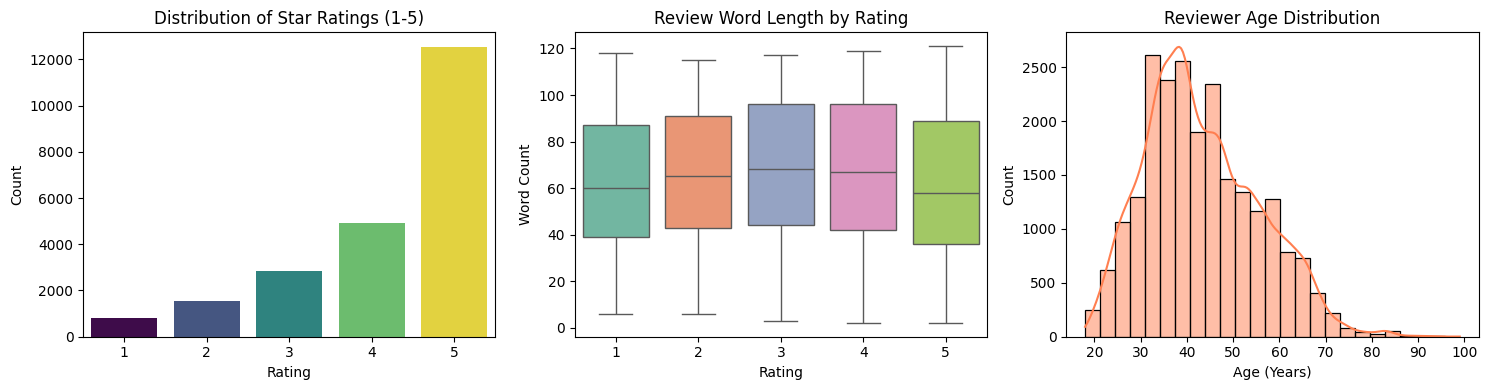

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Rating distribution
sns.countplot(x='Rating', data=df_clean, ax=axes[0], hue='Rating', palette='viridis', legend=False)
axes[0].set_title('Distribution of Star Ratings (1-5)')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')

# 2. Review length by rating
sns.boxplot(x='Rating', y='review_length', data=df_clean, ax=axes[1], hue='Rating', palette='Set2', legend=False)
axes[1].set_title('Review Word Length by Rating')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Word Count')

# 3. Reviewer Age distribution
sns.histplot(df_clean['Age'], bins=25, kde=True, ax=axes[2], color='coral')
axes[2].set_title('Reviewer Age Distribution')
axes[2].set_xlabel('Age (Years)')

plt.tight_layout()
plt.savefig('eda_clothing.png', dpi=300)
plt.show()

In [7]:
num_cols = ['Age', 'log_pos_feedback', 'review_length']
cat_cols = ['Division Name', 'Department Name', 'Class Name']
text_col = 'full_text'

X = df_clean[num_cols + cat_cols + [text_col]]
y = df_clean['Rating']

# First split: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

# Second split: 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print("Train size:", len(X_train), "Val size:", len(X_val), "Test size:", len(X_test))

# Vocabulary size check on training split only
vec_check = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words='english')
vec_check.fit(X_train[text_col])
print("Vocabulary size (capped TF-IDF):", len(vec_check.vocabulary_))

Train size: 15848 Val size: 3396 Test size: 3397
Vocabulary size (capped TF-IDF): 15000


In [8]:
def build_preprocessor(mode='combined'):
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    text_pipe = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words='english')

    if mode == 'structured':
        return ColumnTransformer([
            ('num', num_pipe, num_cols),
            ('cat', cat_pipe, cat_cols)
        ])
    elif mode == 'text':
        return ColumnTransformer([
            ('txt', text_pipe, text_col)
        ])
    else:
        return ColumnTransformer([
            ('num', num_pipe, num_cols),
            ('cat', cat_pipe, cat_cols),
            ('txt', text_pipe, text_col)
        ])

# Tune C for Logistic Regression on validation set
best_c = 1.0
best_val_f1 = 0
for c_val in [0.5, 1.0, 2.0, 5.0]:
    pipe = Pipeline([
        ('prep', build_preprocessor('combined')),
        ('clf', LogisticRegression(C=c_val, max_iter=1000, random_state=SEED))
    ])
    pipe.fit(X_train, y_train)
    val_f1 = f1_score(y_val, pipe.predict(X_val), average='macro')
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_c = c_val

print("Best Logistic Regression C on validation:", best_c, "Val Macro-F1:", round(best_val_f1, 4))

# Compare required models on Test Set
models_b3 = [
    ('Logistic Regression (Default)', LogisticRegression(C=best_c, max_iter=1000, random_state=SEED)),
    ('Logistic Regression (Balanced)', LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=SEED)),
    ('Linear SVM (Default)', LinearSVC(C=0.5, random_state=SEED)),
    ('Linear SVM (Balanced)', LinearSVC(C=0.5, class_weight='balanced', random_state=SEED)),
    ('Random Forest (Balanced)', RandomForestClassifier(n_estimators=200, max_depth=25, class_weight='balanced', random_state=SEED, n_jobs=-1))
]

test_results = []
for name, clf in models_b3:
    pipe = Pipeline([('prep', build_preprocessor('combined')), ('clf', clf)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    acc = accuracy_score(y_test, preds)
    macro_f1 = f1_score(y_test, preds, average='macro')
    weighted_f1 = f1_score(y_test, preds, average='weighted')
    ord_mae = mean_absolute_error(y_test, preds)

    test_results.append(dict(
        Model=name,
        Accuracy=round(acc, 4),
        Macro_F1=round(macro_f1, 4),
        Weighted_F1=round(weighted_f1, 4),
        Ordinal_MAE=round(ord_mae, 4)
    ))
    if name == 'Logistic Regression (Balanced)':
        best_model_preds = preds
        best_pipe = pipe

display(pd.DataFrame(test_results))
print("\\nPer-Class Report (Best Macro-F1 Model - Logistic Regression Balanced):")
print(classification_report(y_test, best_model_preds, digits=4))

Best Logistic Regression C on validation: 2.0 Val Macro-F1: 0.43


,Model,Accuracy,Macro_F1,Weighted_F1,Ordinal_MAE
0,Logistic Regression (Default),0.6429,0.4204,0.6136,0.4636
1,Logistic Regression (Balanced),0.6208,0.4722,0.6294,0.4689
2,Linear SVM (Default),0.6385,0.4187,0.6094,0.4669
3,Linear SVM (Balanced),0.6317,0.4492,0.6246,0.4586
4,Random Forest (Balanced),0.5946,0.3990,0.5749,0.5346


\nPer-Class Report (Best Macro-F1 Model - Logistic Regression Balanced):
              precision    recall  f1-score   support

           1     0.3828    0.3984    0.3904       123
           2     0.3052    0.3276    0.3160       232
           3     0.3783    0.4363    0.4053       424
           4     0.4252    0.4586    0.4413       737
           5     0.8416    0.7767    0.8079      1881

    accuracy                         0.6208      3397
   macro avg     0.4666    0.4795    0.4722      3397
weighted avg     0.6402    0.6208    0.6294      3397



--- Ablation Study Results ---


,Feature_Set,Accuracy,Macro_F1,Ordinal_MAE
0,Structured,0.2797,0.2021,1.4734
1,Text,0.6200,0.4638,0.4692
2,Combined,0.6208,0.4722,0.4689


\n--- 3-Class Framing Results ---
3-Class Accuracy: 0.8122
3-Class Macro-F1: 0.6366


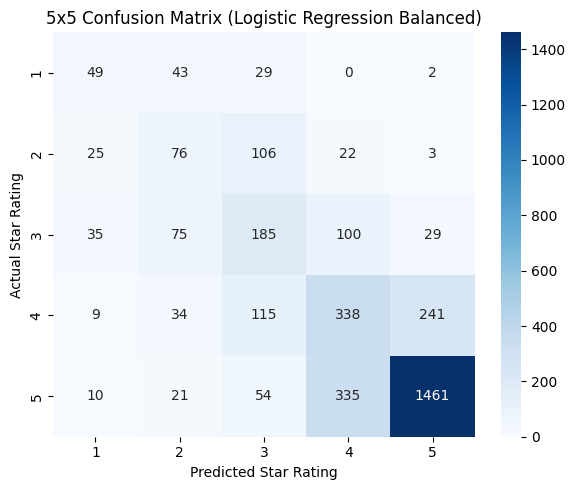

\n--- Sample Misclassified Reviews ---
Actual: 4 | Predicted: 5 | Dept: Dresses
Review: I'm over 50 and over 150 lbs and love this dress! The large is perfect for me and is just my style - not too baggy but just shapely enough to where to the office with or without le ...\n
Actual: 2 | Predicted: 4 | Dept: Tops
Review: Too sheer If you are over 25, this top probably is not for you. it is absolutely see-thru. great style and beautiful light fabric, but you can see right thru it. ...\n
Actual: 4 | Predicted: 5 | Dept: Tops
Review: Classic and elegant I purchased this online without seeing in person and was pleasantly surprised. i have purchased clothing made from netting with embroidered damask design in the ...\n


In [9]:
# 1. Mandatory Ablation Study: Structured vs Text vs Combined
ablation_rows = []
for mode in ['structured', 'text', 'combined']:
    pipe = Pipeline([
        ('prep', build_preprocessor(mode)),
        ('clf', LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=SEED))
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    ablation_rows.append(dict(
        Feature_Set=mode.capitalize(),
        Accuracy=round(accuracy_score(y_test, preds), 4),
        Macro_F1=round(f1_score(y_test, preds, average='macro'), 4),
        Ordinal_MAE=round(mean_absolute_error(y_test, preds), 4)
    ))

print("--- Ablation Study Results ---")
display(pd.DataFrame(ablation_rows))

# 2. 3-Class Re-framing: Negative (1-2), Neutral (3), Positive (4-5)
mapping_3 = dict([
    (1, 'Negative (1-2)'),
    (2, 'Negative (1-2)'),
    (3, 'Neutral (3)'),
    (4, 'Positive (4-5)'),
    (5, 'Positive (4-5)')
])
y_train_3 = y_train.map(mapping_3)
y_test_3 = y_test.map(mapping_3)

pipe_3class = Pipeline([
    ('prep', build_preprocessor('combined')),
    ('clf', LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=SEED))
])
pipe_3class.fit(X_train, y_train_3)
preds_3 = pipe_3class.predict(X_test)
print("\\n--- 3-Class Framing Results ---")
print("3-Class Accuracy:", round(accuracy_score(y_test_3, preds_3), 4))
print("3-Class Macro-F1:", round(f1_score(y_test_3, preds_3, average='macro'), 4))

# 3. 5x5 Confusion Matrix Figure
cm = confusion_matrix(y_test, best_model_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[1,2,3,4,5], yticklabels=[1,2,3,4,5])
plt.title('5x5 Confusion Matrix (Logistic Regression Balanced)')
plt.xlabel('Predicted Star Rating')
plt.ylabel('Actual Star Rating')
plt.tight_layout()
plt.savefig('cm_clothing.png', dpi=300)
plt.show()

# 4. Three Misclassified Examples for Error Analysis
err_df = X_test.copy()
err_df['Actual'] = y_test
err_df['Predicted'] = best_model_preds
misclassified = err_df[err_df['Actual'] != err_df['Predicted']]
print("\\n--- Sample Misclassified Reviews ---")
for idx, row in misclassified.head(3).iterrows():
    print("Actual:", row['Actual'], "| Predicted:", row['Predicted'], "| Dept:", row['Department Name'])
    print("Review:", row['full_text'][:180], "...\\n")